# DM-2 : Boosting et cartes de saillance

Description rapide

In [61]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd

## 0. Import du dataset MNIST

In [62]:
from sklearn.datasets import fetch_openml

X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)
y = y.astype(int)

(70000, 784) (70000,)


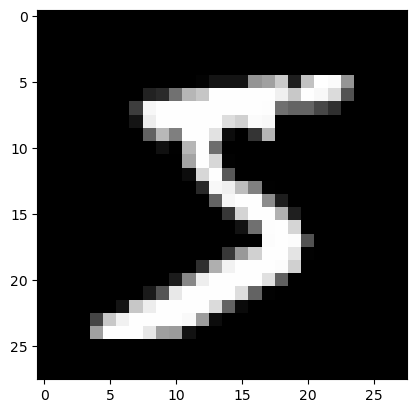

In [40]:
print(X.shape, y.shape)
plt.imshow(X[0, :].reshape(28, 28), cmap="Greys_r")

In [41]:
np.unique_counts(y)

UniqueCountsResult(values=array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), counts=array([6903, 7877, 6990, 7141, 6824, 6313, 6876, 7293, 6825, 6958]))

- 70000 images aplatis de taille (1, 784) ((28,28) à l'origine).
- Chiffre entre 0 et 9.

## 1. Utilisation d’un algorithme de boosting sur de la reconnaissance de chiﬀres manuscrits

Séparation du dataset en set d'entrainnement et de test. \
75 % en entrainnement et 25% en test, car nous avons un grand nombre d'images.

In [69]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

### A. Première modélisation

Première modelisation avec Adaboost :
- Abre de décision (profondeur maximal de 20)
- nombre d'estimateur : 20
- learning rate : 0.5

In [70]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

Tree_adaboost = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=20),
                                  n_estimators=20,
                                  learning_rate=0.5,
                                  random_state=42)

Tree_adaboost.fit(X_train, y_train)

Tree_adaboost_score = Tree_adaboost.score(X_test, y_test)
print(f"AdaBoost score: {Tree_adaboost_score}")

AdaBoost score: 0.9636571428571429


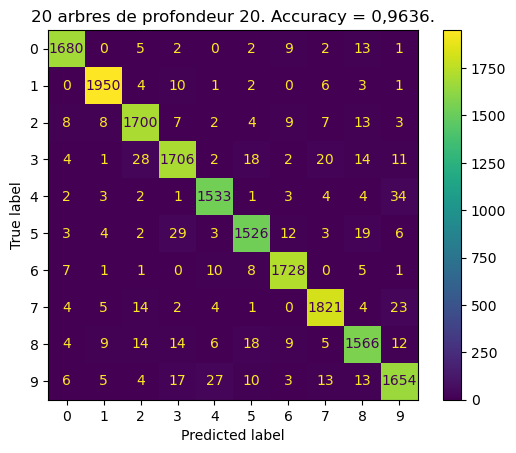

In [79]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm_Tree_adaboost = confusion_matrix(y_test, Tree_adaboost.predict(X_test))
cm_Tree_adaboost_disp = ConfusionMatrixDisplay(cm_Tree_adaboost)
cm_Tree_adaboost_disp.plot()
cm_Tree_adaboost_disp.ax_.set_title("20 arbres de profondeur 20. Accuracy = 0,9636.")
plt.savefig("images/cm_Tree_adaboost.png", dpi=300, bbox_inches="tight")

<img src="images/cm_Tree_adaboost.png" alt= "Matrice de confusion décision stump" width="500">

Avec ce premier modèle, on obtient un un score de 0,9636 en test. La matrice de confusion montre de bon resultats avec une majorité de bon classement, surtout pour les 1. Les chiffres les moins bien classées sont les 4, 5 et 8. \
\
Les principales confusions sont :
- les 5 confondu avec des 3
- les 3 confondu avec des 2
- les 9 confondu avec des 4

### B. Gridsearch en variant les classifier faibles

Stratification pour la cross-validation.

In [65]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds = skf.split(X_train, y_train)

Réglage des paramètres à teste en GridSearch.

In [64]:
from sklearn.linear_model import Perceptron

estimators = {"stump": DecisionTreeClassifier(max_depth=1),
              "tree_d2": DecisionTreeClassifier(max_depth=2),
              "tree_d3": DecisionTreeClassifier(max_depth=3),
              "tree_d5": DecisionTreeClassifier(max_depth=5),
              "tree_d20": DecisionTreeClassifier(max_depth=20),
              "perceptron": Perceptron(max_iter=1000, tol=1e-3, random_state=42)}

params = {"n_estimators" : [5, 10, 20]}

Réalisation de la cross validation GridSearch.

[{'estimator': 'stump', 'accuracy': np.float64(0.49241904761904765), 'n_estimators': 20}]


AttributeError: 'ConfusionMatrixDisplay' object has no attribute 'ax_'

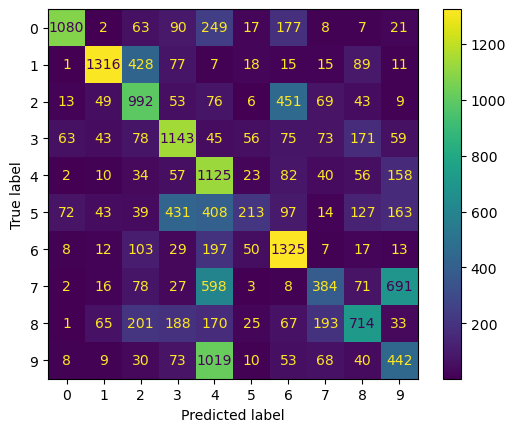

In [80]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

results = []

for estimator_name, estimator in estimators.items():
    ada_boost = AdaBoostClassifier(estimator=estimator, random_state=42)

    grid = GridSearchCV(estimator=ada_boost, param_grid=params, scoring="accuracy", cv=skf, n_jobs=-1)

    grid.fit(X_train, y_train)
    acc = grid.best_score_
    best = grid.best_estimator_

    # Resultats des cross val
    results.append({"estimator" : estimator_name, "accuracy" : acc, "n_estimators" : grid.best_params_["n_estimators"]})
    print(results)

    # Matrice de confusion sur le test
    cm = confusion_matrix(y_test, best.predict(X_test))
    ConfusionMatrixDisplay(cm).plot()
    ConfusionMatrixDisplay(cm).ax_.set_title(f"{grid.best_params_["n_estimators"]} X {estimator_name}. Accuracy = {acc}.")
    plt.savefig(f"images/cm_{estimator_name}.png", dpi=300, bbox_inches="tight")

In [68]:
df_results = pd.DataFrame(results, columns=["estimator", "accuracy", "n_estimators"])
df_results

,estimator,accuracy,n_estimators
0,stump,0.492419,20
1,tree_d2,0.699467,20
2,tree_d3,0.784381,20
3,tree_d5,0.866057,20
4,tree_d20,0.957410,20
5,perceptron,0.844419,20


<img src="images/cm_stump.png" alt= "Matrice de confusion décision stump" width="500">

<img src="images/cm_tree_d2.png" alt= "Matrice de confusion arbre de profondeur 2" width="500">

<img src="images/cm_tree_d3.png" alt= "Matrice de confusion arbre de profondeur 3" width="500">

<img src="images/cm_tree_d5.png" alt= "Matrice de confusion arbre de profondeur 5" width="500">

<img src="images/cm_tree_d20.png" alt= "Matrice de confusion arbre de profondeur 20" width="500">

<img src="images/cm_perceptron.png" alt= "Matrice de confusion perceptron" width="500">

### C. Etude de classes binaires

On test ici les classes :
- 9 vs 4
- 5 vs 3

#### 1. 9 vs 4

In [ ]:
mask_9v4 = (y==9) | (y==4)
X_9v4, y_9v4 = X[mask_9v4], (y[mask_9v4] == 9).astype(int)
X_9v4_train, X_9v4_test, y_9v4_train, y_9v4_test = train_test_split(X_9v4, y_9v4, test_size=0.25, random_state=42)


In [ ]:
results_9v4 = []

for estimator_name, estimator in estimators.items():
    ada_boost = AdaBoostClassifier(estimator=estimator, random_state=42)

    grid = GridSearchCV(estimator=ada_boost, param_grid={"n_estimators" : [20]}, scoring="accuracy", cv=skf, n_jobs=-1)

    grid.fit(X_9v4_train, y_9v4_train)
    acc = grid.best_score_

    results_9v4.append({"estimator" : estimator_name, "accuracy" : acc, "n_estimators" : grid.best_params_["n_estimators"]})
    print(results_9v4)

#### 2. 5 vs 3

In [ ]:
mask_5v3 = (y==5) | (y==3)
X_5v3, y_5v3 = X[mask_5v3], (y[mask_5v3] == 5).astype(int)
X_5v3_train, X_5v3_test, y_5v3_train, y_5v3_test = train_test_split(X_5v3, y_5v3, test_size=0.25, random_state=42)

In [ ]:
results_5v3 = []

for estimator_name, estimator in estimators.items():
    ada_boost = AdaBoostClassifier(estimator=estimator, random_state=42)

    grid = GridSearchCV(estimator=ada_boost, param_grid={"n_estimators" : [20]}, scoring="accuracy", cv=skf, n_jobs=-1)

    grid.fit(X_5v3_train, y_5v3_train)
    acc = grid.best_score_

    results_5v3.append({"estimator" : estimator_name, "accuracy" : acc, "n_estimators" : grid.best_params_["n_estimators"]})
    print(results_5v3)

## 2. Réalisation de cartes de saillance